In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("Synthetic_Library_Operations_Analytics.csv")

df.head()

,record_id,month,branch,patron_age_group,material_type,program_type,checkouts,program_attendance,computer_sessions,wifi_sessions,reference_questions,new_library_cards,high_activity_flag
0,170,2024-01-01,Central,Adult,Print Book,Children's,38,11,9,26,1,4,No
1,454,2024-01-01,Central,Adult,Print Book,Career,37,12,9,27,5,6,No
2,465,2024-01-01,Central,Adult,Audiobook,Technology,22,13,7,23,6,1,No
3,790,2024-01-01,Central,Adult,eBook,Career,26,15,13,15,11,4,No
4,801,2024-01-01,Central,Adult,Audiobook,Technology,24,9,14,15,7,2,No


In [3]:
df.shape

(20000, 13)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   record_id            20000 non-null  int64
 1   month                20000 non-null  str  
 2   branch               20000 non-null  str  
 3   patron_age_group     20000 non-null  str  
 4   material_type        20000 non-null  str  
 5   program_type         20000 non-null  str  
 6   checkouts            20000 non-null  int64
 7   program_attendance   20000 non-null  int64
 8   computer_sessions    20000 non-null  int64
 9   wifi_sessions        20000 non-null  int64
 10  reference_questions  20000 non-null  int64
 11  new_library_cards    20000 non-null  int64
 12  high_activity_flag   20000 non-null  str  
dtypes: int64(7), str(6)
memory usage: 2.7 MB


In [5]:
df["month"] = pd.to_datetime(df["month"])

df["month"].dtype

dtype('<M8[us]')

In [6]:
df.isnull().sum()

record_id              0
month                  0
branch                 0
patron_age_group       0
material_type          0
program_type           0
checkouts              0
program_attendance     0
computer_sessions      0
wifi_sessions          0
reference_questions    0
new_library_cards      0
high_activity_flag     0
dtype: int64

In [7]:
df.describe()

,record_id,month,checkouts,program_attendance,computer_sessions,wifi_sessions,reference_questions,new_library_cards
count,20000.000000,20000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,10000.500000,2025-06-12 13:42:48.960000,24.498350,13.186700,9.441300,17.251600,6.203050,3.787250
min,1.000000,2024-01-01 00:00:00,3.000000,0.000000,0.000000,2.000000,0.000000,0.000000
25%,5000.750000,2024-09-01 00:00:00,19.000000,10.000000,7.000000,14.000000,4.000000,2.000000
50%,10000.500000,2025-06-01 00:00:00,24.000000,13.000000,9.000000,17.000000,6.000000,4.000000
75%,15000.250000,2026-03-01 00:00:00,30.000000,16.000000,11.000000,20.000000,8.000000,5.000000
max,20000.000000,2026-12-01 00:00:00,58.000000,34.000000,25.000000,41.000000,18.000000,14.000000
std,5773.647028,NaN,8.231688,4.601522,3.245255,4.673691,2.559423,1.986979


In [8]:
checkouts_by_branch = df.groupby("branch")["checkouts"].sum().sort_values(ascending=False)

checkouts_by_branch

branch
Central    146715
North       93147
East        93058
South       80030
West        77017
Name: checkouts, dtype: int64

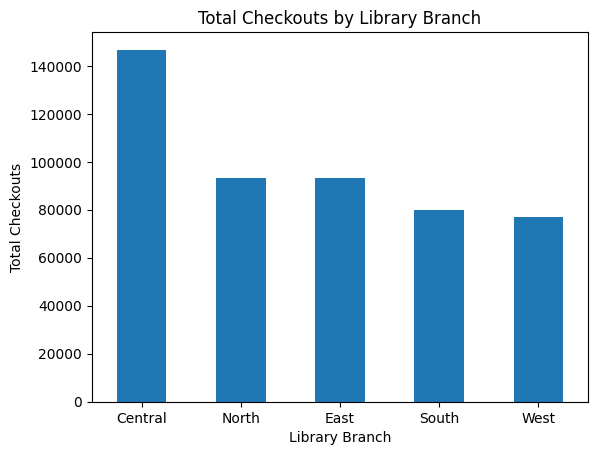

In [9]:
checkouts_by_branch.plot(kind="bar")

plt.title("Total Checkouts by Library Branch")
plt.xlabel("Library Branch")
plt.ylabel("Total Checkouts")
plt.xticks(rotation=0)
plt.show()

In [10]:
attendance_by_program = (
    df.groupby("program_type")["program_attendance"]
    .sum()
    .sort_values(ascending=False)
)

attendance_by_program

program_type
Children's    86778
Community     61292
Technology    43411
Book Club     40155
Career        32098
Name: program_attendance, dtype: int64

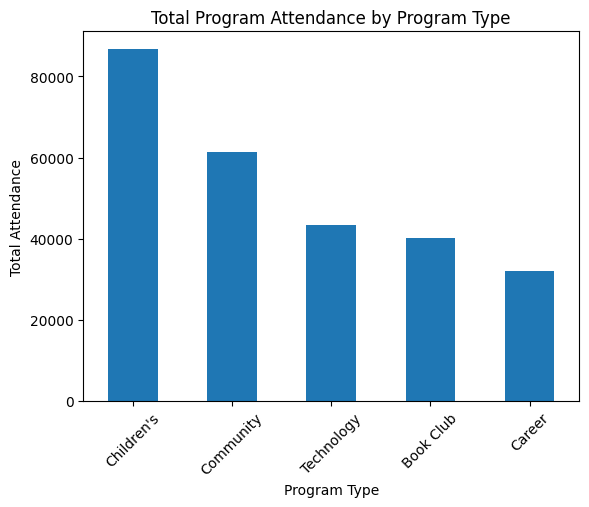

In [11]:
attendance_by_program.plot(kind="bar")

plt.title("Total Program Attendance by Program Type")
plt.xlabel("Program Type")
plt.ylabel("Total Attendance")
plt.xticks(rotation=45)
plt.show()

In [12]:
checkouts_by_material = (
    df.groupby("material_type")["checkouts"]
    .sum()
    .sort_values(ascending=False)
)

checkouts_by_material

material_type
Print Book    296792
eBook          99065
Audiobook      67901
DVD            26209
Name: checkouts, dtype: int64

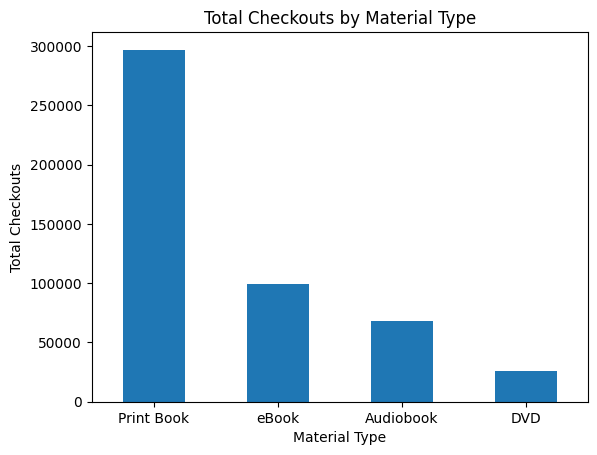

In [13]:
checkouts_by_material.plot(kind="bar")

plt.title("Total Checkouts by Material Type")
plt.xlabel("Material Type")
plt.ylabel("Total Checkouts")
plt.xticks(rotation=0)
plt.show()

In [14]:
monthly_checkouts = df.groupby("month")["checkouts"].sum()

monthly_checkouts.head()

month
2024-01-01    13835
2024-02-01    13388
2024-03-01    12614
2024-04-01    13502
2024-05-01    13313
Name: checkouts, dtype: int64

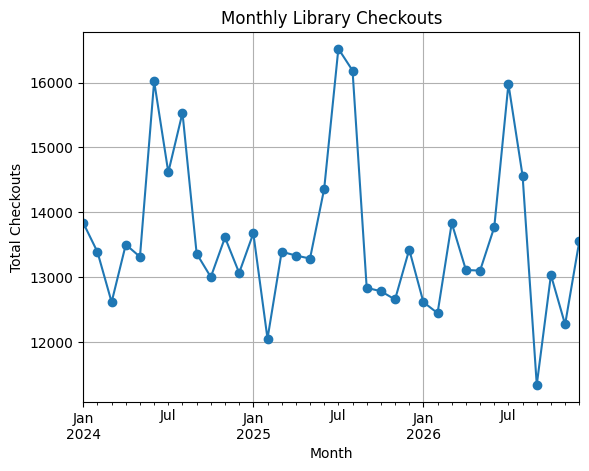

In [15]:
monthly_checkouts.plot(kind="line", marker="o")

plt.title("Monthly Library Checkouts")
plt.xlabel("Month")
plt.ylabel("Total Checkouts")
plt.grid(True)
plt.show()

In [16]:
computer_by_branch = (
    df.groupby("branch")["computer_sessions"]
    .sum()
    .sort_values(ascending=False)
)

computer_by_branch

branch
Central    56246
North      36237
East       36053
South      30626
West       29664
Name: computer_sessions, dtype: int64

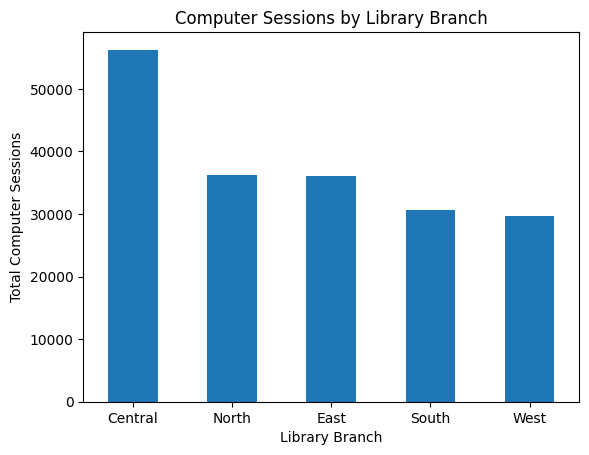

In [17]:
computer_by_branch.plot(kind="bar")

plt.title("Computer Sessions by Library Branch")
plt.xlabel("Library Branch")
plt.ylabel("Total Computer Sessions")
plt.xticks(rotation=0)
plt.show()

In [18]:
wifi_by_branch = (
    df.groupby("branch")["wifi_sessions"]
    .sum()
    .sort_values(ascending=False)
)

wifi_by_branch

branch
Central    102818
East        65790
North       65390
South       56764
West        54270
Name: wifi_sessions, dtype: int64

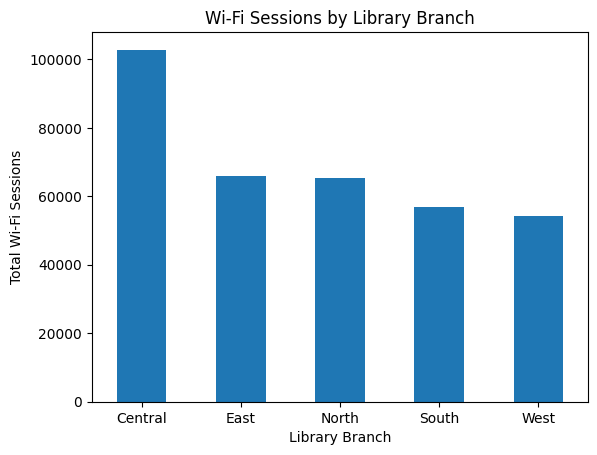

In [19]:
wifi_by_branch.plot(kind="bar")

plt.title("Wi-Fi Sessions by Library Branch")
plt.xlabel("Library Branch")
plt.ylabel("Total Wi-Fi Sessions")
plt.xticks(rotation=0)
plt.show()

In [20]:
cards_by_branch = (
    df.groupby("branch")["new_library_cards"]
    .sum()
    .sort_values(ascending=False)
)

cards_by_branch



branch
Central    22738
North      14560
East       14087
South      12343
West       12017
Name: new_library_cards, dtype: int64

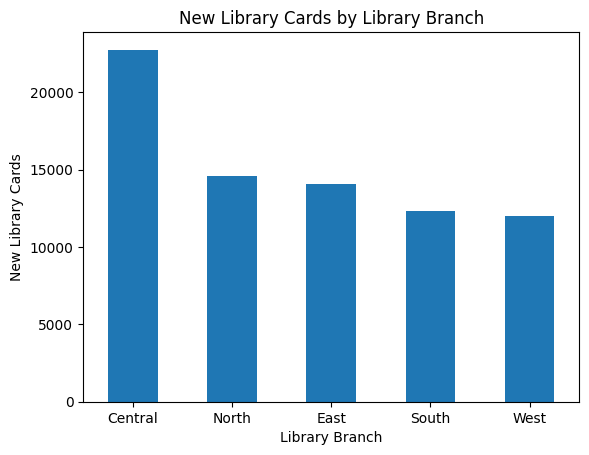

In [21]:
cards_by_branch.plot(kind="bar")

plt.title("New Library Cards by Library Branch")
plt.xlabel("Library Branch")
plt.ylabel("New Library Cards")
plt.xticks(rotation=0)
plt.show()

In [22]:
reference_by_branch = (
    df.groupby("branch")["reference_questions"]
    .sum()
    .sort_values(ascending=False)
)

reference_by_branch

branch
Central    36966
East       23977
North      23409
South      20154
West       19555
Name: reference_questions, dtype: int64

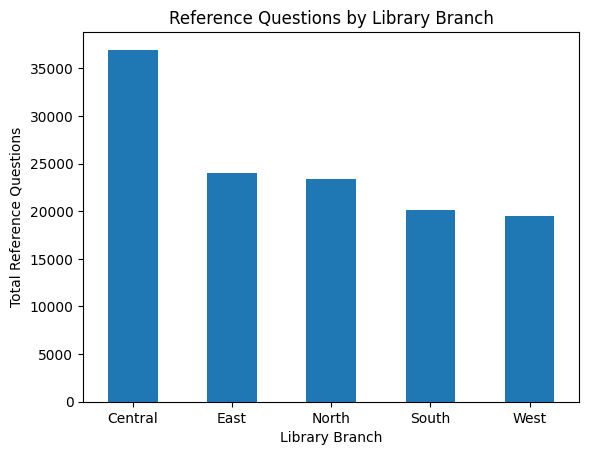

In [23]:
reference_by_branch.plot(kind="bar")

plt.title("Reference Questions by Library Branch")
plt.xlabel("Library Branch")
plt.ylabel("Total Reference Questions")
plt.xticks(rotation=0)
plt.show()

In [24]:
branch_summary = df.groupby("branch")[
    [
        "checkouts",
        "program_attendance",
        "computer_sessions",
        "wifi_sessions",
        "reference_questions",
        "new_library_cards"
    ]
].sum()

branch_summary

,checkouts,program_attendance,computer_sessions,wifi_sessions,reference_questions,new_library_cards
branch,,,,,,
Central,146715,78705,56246,102818,36966,22738
East,93058,50087,36053,65790,23977,14087
North,93147,50207,36237,65390,23409,14560
South,80030,43308,30626,56764,20154,12343
West,77017,41427,29664,54270,19555,12017


In [25]:
checkouts_by_age = (
    df.groupby("patron_age_group")["checkouts"]
    .sum()
    .sort_values(ascending=False)
)

checkouts_by_age

patron_age_group
Adult     237877
Child      97867
Senior     86952
Teen       67271
Name: checkouts, dtype: int64

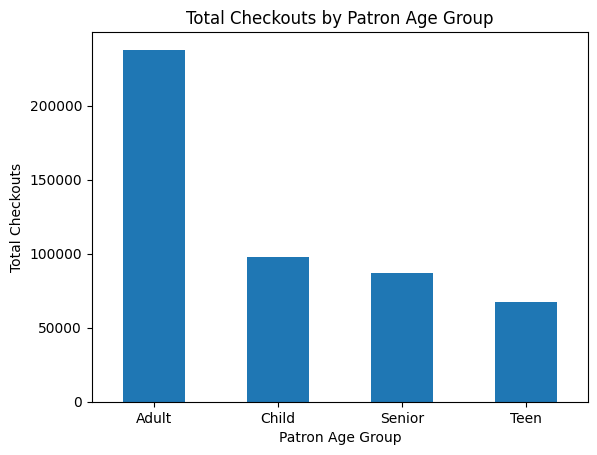

In [26]:
checkouts_by_age.plot(kind="bar")

plt.title("Total Checkouts by Patron Age Group")
plt.xlabel("Patron Age Group")
plt.ylabel("Total Checkouts")
plt.xticks(rotation=0)
plt.show()

In [27]:
df["high_activity_flag"].value_counts()

high_activity_flag
No     19564
Yes      436
Name: count, dtype: int64

In [28]:
high_activity_by_branch = (
    df[df["high_activity_flag"] == "Yes"]
    .groupby("branch")
    .size()
    .sort_values(ascending=False)
)

high_activity_by_branch

branch
Central    395
North       28
East        10
South        2
West         1
dtype: int64

In [29]:
activity_columns = [
    "checkouts",
    "program_attendance",
    "computer_sessions",
    "wifi_sessions",
    "reference_questions",
    "new_library_cards"
]

df[activity_columns].corr().round(2)

,checkouts,program_attendance,computer_sessions,wifi_sessions,reference_questions,new_library_cards
checkouts,1.00,0.14,0.10,0.19,0.08,0.10
program_attendance,0.14,1.00,0.09,0.17,0.08,0.10
computer_sessions,0.10,0.09,1.00,0.11,0.09,0.05
wifi_sessions,0.19,0.17,0.11,1.00,0.10,0.12
reference_questions,0.08,0.08,0.09,0.10,1.00,0.05
new_library_cards,0.10,0.10,0.05,0.12,0.05,1.00


## Conclusion

The exploratory analysis identified several patterns in the synthetic library operations data:

- Central had the highest overall activity across several service measures, including checkouts, computer sessions, Wi-Fi sessions, reference questions, and new library cards.
- Children's programs had the highest total program attendance.
- Print books accounted for the largest number of material checkouts.
- Adults represented the age group with the highest total checkouts.
- Monthly checkout activity showed variation over time, indicating periods of higher and lower library demand.
- Most high-activity records occurred at the Central branch.
- Correlations among the major activity measures were generally weak, suggesting that circulation, technology use, programming, and other services represent different aspects of library engagement.

These findings can help support decisions related to staffing, programming, technology resources, collection planning, and branch operations.

## Conclusion

The exploratory analysis identified several patterns in the synthetic library operations data:

- Central had the highest overall activity across several service measures, including checkouts, computer sessions, Wi-Fi sessions, reference questions, and new library cards.
- Children's programs had the highest total program attendance.
- Print books accounted for the largest number of material checkouts.
- Adults represented the age group with the highest total checkouts.
- Monthly checkout activity showed variation over time, indicating periods of higher and lower library demand.
- Most high-activity records occurred at the Central branch.
- Correlations among the major activity measures were generally weak, suggesting that circulation, technology use, programming, and other services represent different aspects of library engagement.

These findings can help support decisions related to staffing, programming, technology resources, collection planning, and branch operations.